# Quantum Advantage for QUBO — Grover Adaptive Search
**Ahmed Raza · Student No. 2026210028**


## 1. Problem: Max-Cut as a QUBO

In [5]:
%pip install networkx

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 39.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [6]:
import numpy as np, networkx as nx, matplotlib.pyplot as plt

def maxcut_qubo(G):
    """Q such that cut(x) = -x^T Q x:  Q_ii = -deg(i),  Q_ij = Q_ji = 1 for every edge."""
    n = G.number_of_nodes(); Q = np.zeros((n, n))
    for i, j in G.edges():
        Q[i, i] -= 1; Q[j, j] -= 1; Q[i, j] += 1; Q[j, i] += 1
    return Q

def qubo_energies(Q):
    """f(x) = x^T Q x for all 2^n bitstrings (bit 0 = most significant)."""
    n = Q.shape[0]; k = np.arange(2 ** n, dtype=np.int64); f = np.zeros(2 ** n)
    for i in range(n):
        f += Q[i, i] * ((k >> (n - 1 - i)) & 1)
        for j in range(i + 1, n):
            if Q[i, j] != 0:
                f += 2 * Q[i, j] * (((k >> (n - 1 - i)) & (k >> (n - 1 - j))) & 1)
    return f

## 2. Grover Adaptive Search and classical search
Oracle: flip the sign of states with $f(x)<y$. Diffusion: $\psi \to 2\langle s|\psi\rangle|s\rangle-\psi$.
After $k$ steps, $P(\text{marked})=\sin^2((2k+1)\theta)$ with $\sin^2\theta=t/N$. One **query** = one evaluation of $f$.

In [7]:
def grover_state(f, y, k):
    psi = np.full(len(f), len(f) ** -0.5)          # uniform superposition |s>
    sign = np.where(f < y, -1.0, 1.0)              # oracle
    for _ in range(k):
        psi = psi * sign                           # oracle O_y
        psi = 2 * psi.mean() - psi                 # diffusion 2|s><s| - I
    return psi

def grover_measure(f, y, k, rng, exact_statevector=True):
    N = len(f)
    if exact_statevector:                          # full state-vector simulation
        p = grover_state(f, y, k) ** 2
        return rng.choice(N, p=p / p.sum())
    marked = np.flatnonzero(f < y); t = len(marked)   # identical closed form (n > 18)
    if t == 0:
        return rng.integers(N)
    if rng.random() < np.sin((2 * k + 1) * np.arcsin(np.sqrt(t / N))) ** 2:
        return marked[rng.integers(t)]
    while True:
        x = rng.integers(N)
        if f[x] >= y:
            return x

def grover_adaptive_search(f, rng, f_opt, lam=6 / 5, exact_statevector=True):
    """Duerr-Hoyer / GAS with BBHT random iteration counts. Returns queries until the optimum is found."""
    N = len(f); x = rng.integers(N); y = f[x]; queries = 1; m = 1.0
    max_queries = 50 * int(np.sqrt(N)) + 100
    while queries < max_queries and y > f_opt + 1e-9:
        k = rng.integers(0, int(np.ceil(m)))
        x = grover_measure(f, y, k, rng, exact_statevector)
        queries += k + 1                           # k oracle calls + 1 evaluation of f(x)
        if f[x] < y:
            y = f[x]; m = 1.0
        else:
            m = min(lam * m, np.sqrt(N))
    return queries

def classical_random_search(N, M, rng):
    """Random sampling until an optimum appears: Geometric(M/N) queries."""
    return int(rng.geometric(M / N))

## 3. Benchmark (3 graphs × 40 runs per size)

In [8]:
SIZES, N_INST, N_RUNS, SV_MAX = list(range(6, 25, 2)), 3, 40, 18
rng = np.random.default_rng(7)
res = []
for n in SIZES:
    for s in range(N_INST):
        G = nx.random_regular_graph(3, n, seed=500 + 10 * n + s)
        f = qubo_energies(maxcut_qubo(G))
        fo = f.min(); M = int((f == fo).sum()); N = 2 ** n
        gq = [grover_adaptive_search(f, rng, fo, exact_statevector=(n <= SV_MAX)) for _ in range(N_RUNS)]
        cq = [classical_random_search(N, M, rng) for _ in range(N_RUNS)]
        res.append(dict(n=n, N=N, M=M, gas=np.mean(gq), gas_p90=np.percentile(gq, 90), cls=np.mean(cq)))

print(f"{'n':>3} {'M':>5} {'GAS':>8} {'Random':>11} {'Exhaustive':>11} {'vs random':>10} {'vs exhaust.':>11}")
for n in SIZES:
    r = [x for x in res if x["n"] == n]
    g, c, M = np.mean([x["gas"] for x in r]), np.mean([x["cls"] for x in r]), np.mean([x["M"] for x in r])
    print(f"{n:>3} {M:>5.1f} {g:>8,.0f} {c:>11,.0f} {2**n:>11,} {c/g:>9,.0f}x {2**n/g:>10,.0f}x")

  n     M      GAS      Random  Exhaustive  vs random vs exhaust.
  6   4.7        8          18          64         2x          8x
  8   3.3       20          86         256         4x         13x
 10   4.7       35         218       1,024         6x         30x
 12   2.0      105       2,349       4,096        22x         39x
 14   3.3      177       6,483      16,384        37x         93x
 16   5.3      300      23,414      65,536        78x        218x
 18   8.7      508      75,548     262,144       149x        516x
 20   6.7      958     269,759   1,048,576       281x      1,094x
 22  10.7    1,845     854,542   4,194,304       463x      2,273x
 24   5.3    4,088   4,112,993  16,777,216     1,006x      4,104x


## 4. Figures

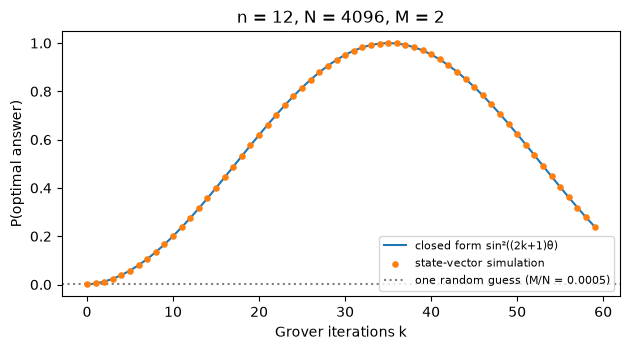

In [9]:
# Fig. 1 - amplitude amplification on a 12-variable QUBO
f12 = qubo_energies(maxcut_qubo(nx.random_regular_graph(3, 12, seed=1)))
fo, N12 = f12.min(), len(f12); M12 = int((f12 == fo).sum())
ks = np.arange(60); th = np.arcsin(np.sqrt(M12 / N12))
p_sim = [(grover_state(f12, fo + 0.5, k)[f12 < fo + 0.5] ** 2).sum() for k in ks]
plt.figure(figsize=(6.4, 3.6))
plt.plot(ks, np.sin((2 * ks + 1) * th) ** 2, label="closed form sin²((2k+1)θ)")
plt.scatter(ks, p_sim, s=14, color="tab:orange", zorder=3, label="state-vector simulation")
plt.axhline(M12 / N12, ls=":", color="gray", label=f"one random guess (M/N = {M12/N12:.4f})")
plt.xlabel("Grover iterations k"); plt.ylabel("P(optimal answer)")
plt.title(f"n = 12, N = {N12}, M = {M12}"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

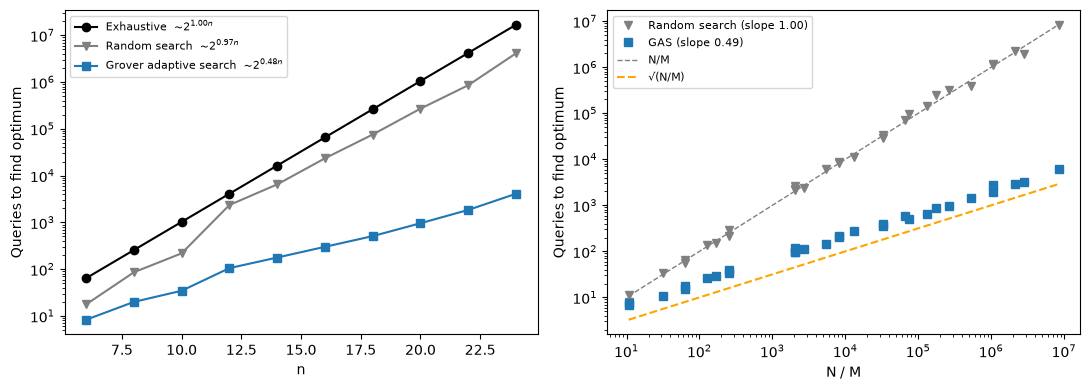

Slope vs N/M:  classical = 1.004,  GAS = 0.494   (theory: 1 and 0.5)


In [10]:
# Fig. 2 - queries to find the optimum
nn = np.array(SIZES)
avg = lambda k: np.array([np.mean([x[k] for x in res if x["n"] == n]) for n in SIZES])
gas, cls, ex = avg("gas"), avg("cls"), 2.0 ** nn
fit = lambda y: np.polyfit(nn, np.log2(y), 1)[0]
NM = np.array([x["N"] / x["M"] for x in res]); g_all = np.array([x["gas"] for x in res]); c_all = np.array([x["cls"] for x in res])
sg, sc = np.polyfit(np.log(NM), np.log(g_all), 1)[0], np.polyfit(np.log(NM), np.log(c_all), 1)[0]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(nn, ex, "o-", color="k", label=f"Exhaustive  ~$2^{{{fit(ex):.2f}n}}$")
ax[0].semilogy(nn, cls, "v-", color="gray", label=f"Random search  ~$2^{{{fit(cls):.2f}n}}$")
ax[0].semilogy(nn, gas, "s-", color="tab:blue", label=f"Grover adaptive search  ~$2^{{{fit(gas):.2f}n}}$")
ax[0].set_xlabel("n"); ax[0].set_ylabel("Queries to find optimum"); ax[0].legend(fontsize=8)
xs = np.logspace(np.log10(NM.min()), np.log10(NM.max()), 50)
ax[1].loglog(NM, c_all, "v", color="gray", label=f"Random search (slope {sc:.2f})")
ax[1].loglog(NM, g_all, "s", color="tab:blue", label=f"GAS (slope {sg:.2f})")
ax[1].loglog(xs, xs, "--", color="gray", lw=1, label="N/M"); ax[1].loglog(xs, np.sqrt(xs), "--", color="orange", label="√(N/M)")
ax[1].set_xlabel("N / M"); ax[1].set_ylabel("Queries to find optimum"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"Slope vs N/M:  classical = {sc:.3f},  GAS = {sg:.3f}   (theory: 1 and 0.5)")

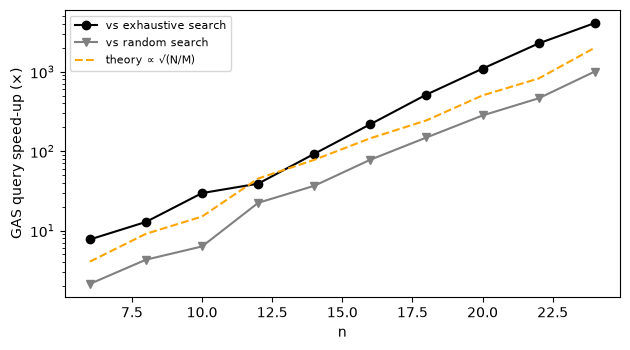

Speed-up at n = 24: 1,006x vs random, 4,104x vs exhaustive


In [11]:
# Fig. 3 - speed-up
plt.figure(figsize=(6.4, 3.6))
plt.semilogy(nn, ex / gas, "o-", color="k", label="vs exhaustive search")
plt.semilogy(nn, cls / gas, "v-", color="gray", label="vs random search")
theory = [np.mean([np.sqrt(x["N"] / x["M"]) for x in res if x["n"] == n]) for n in SIZES]
plt.semilogy(nn, theory, "--", color="orange", label="theory ∝ √(N/M)")
plt.xlabel("n"); plt.ylabel("GAS query speed-up (×)"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"Speed-up at n = 24: {cls[-1]/gas[-1]:,.0f}x vs random, {ex[-1]/gas[-1]:,.0f}x vs exhaustive")